# IEEE 34-Bus Voltage Profile: Clean vs FDIA
**Per-phase (A/B/C) | Dashed = Clean | Solid = FDIA**

### Steps
1. Put `PROFIL_1.CSV` in the **same folder** as this notebook
2. Change `CSV_PATH` or `HOUR` at the top of the cell if needed
3. Press **Shift + Enter** — PNG and PDF are saved automatically


Loaded 79,920 rows from C:\Users\ISLAS2\Downloads\profile_voltage_bus_phase_34bus.csv
Hour=23, scenarios=15. Plotting...
Saved: voltage_profile_hour23.png
Saved: voltage_profile_hour23.pdf


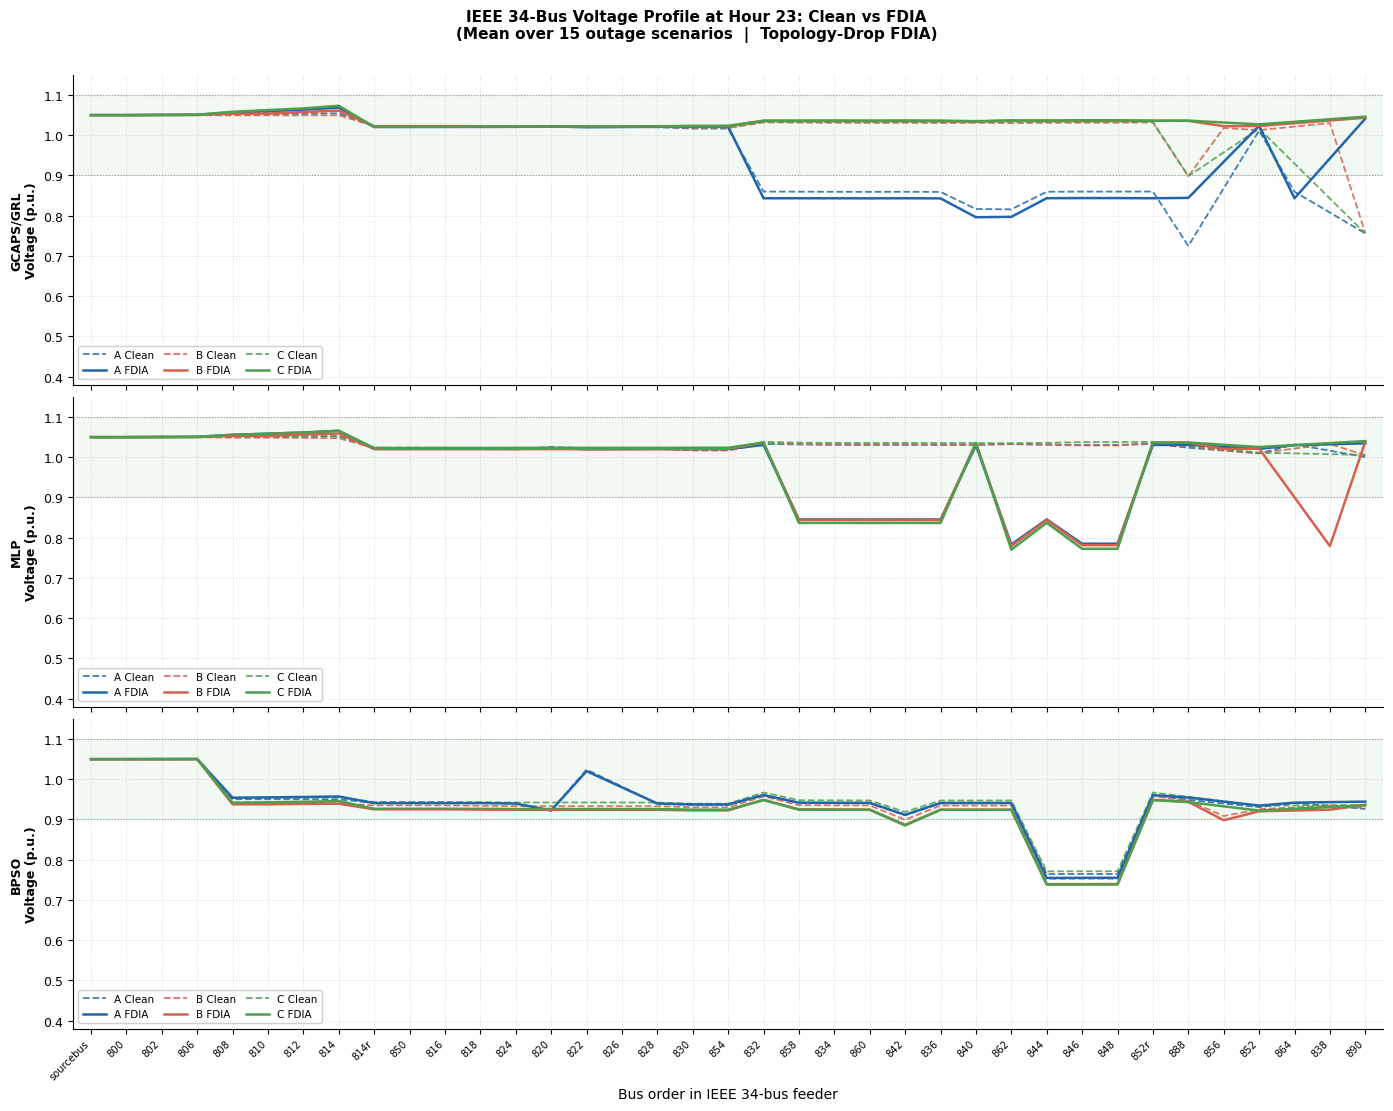

Done.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

# ================================================================
# USER SETTINGS — only change these two lines
# ================================================================
CSV_PATH = r'C:\Users\ISLAS2\Downloads\profile_voltage_bus_phase_34bus.csv'
HOUR     = 23            # <-- hour to plot (0 to 23)
# ================================================================

SAVE_PNG   = True
SAVE_PDF   = True
OUTPUT_PNG = f'voltage_profile_hour{HOUR}.png'
OUTPUT_PDF = f'voltage_profile_hour{HOUR}.pdf'

METHODS  = ['GCAPS', 'MLP', 'BPSO']
LABELS   = {'GCAPS': 'GCAPS/GRL', 'MLP': 'MLP', 'BPSO': 'BPSO'}
PHASES   = ['A', 'B', 'C']
PH_COLOR = {'A': '#2166ac', 'B': '#d6604d', 'C': '#4d9e4d'}
V_MIN, V_MAX = 0.90, 1.10

# ── Load ─────────────────────────────────────────────────────────
df = pd.read_csv(CSV_PATH)
print(f'Loaded {len(df):,} rows from {CSV_PATH}')

bus_order = df.drop_duplicates('bus')[['bus','bus_index']].sort_values('bus_index')
bus_list  = bus_order['bus'].tolist()
bus_pos   = {b: i for i, b in enumerate(bus_list)}

h   = df[df['hour'] == HOUR].copy()
agg = (h.groupby(['paper_method_label','mode','bus','bus_index','phase','phase_active'])
         ['voltage_pu'].mean().reset_index())
n_seeds = df['scenario_seed'].nunique()
print(f'Hour={HOUR}, scenarios={n_seeds}. Plotting...')

# ── Plot ─────────────────────────────────────────────────────────
plt.rcParams.update({
    'font.family':'DejaVu Sans', 'font.size':9,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.linewidth':0.8, 'axes.grid':True,
    'grid.alpha':0.35, 'grid.linestyle':'--', 'grid.linewidth':0.5,
    'xtick.direction':'out', 'ytick.direction':'out',
    'figure.facecolor':'white',
})

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
fig.suptitle(
    f'IEEE 34-Bus Voltage Profile at Hour {HOUR}: Clean vs FDIA\n'
    f'(Mean over {n_seeds} outage scenarios  |  Topology-Drop FDIA)',
    fontsize=11, fontweight='bold', y=1.005
)

for ax, method in zip(axes, METHODS):
    sub = agg[agg['paper_method_label'] == method]
    for phase in PHASES:
        col = PH_COLOR[phase]
        for mode, ls, lw, alpha, zorder in [
            ('clean_dynamic',    '--', 1.3, 0.85, 2),
            ('attacked_dynamic', '-',  1.8, 1.00, 3),
        ]:
            rows = (sub[(sub['mode']==mode) & (sub['phase']==phase)]
                      .sort_values('bus_index').copy())
            rows_active = rows[rows['phase_active'] == 1]
            xs = [bus_pos[b] for b in rows_active['bus'].values]
            ys = rows_active['voltage_pu'].values
            mode_lbl = 'Clean' if mode == 'clean_dynamic' else 'FDIA'
            ax.plot(xs, ys, color=col, ls=ls, lw=lw, alpha=alpha,
                    label=f'{phase} {mode_lbl}', zorder=zorder)

    ax.axhspan(V_MIN, V_MAX, alpha=0.05, color='green', zorder=1)
    ax.axhline(V_MIN, color='gray', lw=0.8, ls=':', alpha=0.7)
    ax.axhline(V_MAX, color='gray', lw=0.8, ls=':', alpha=0.7)
    ax.set_ylim(0.38, 1.15)
    ax.set_ylabel(f'{LABELS[method]}\nVoltage (p.u.)', fontsize=9, fontweight='bold')
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(0.1))
    handles, labels_leg = ax.get_legend_handles_labels()
    ax.legend(handles, labels_leg, fontsize=7.5, ncol=3,
              loc='lower left', framealpha=0.92,
              handlelength=2.2, columnspacing=1.0)

axes[-1].set_xticks(range(len(bus_list)))
axes[-1].set_xticklabels(bus_list, rotation=45, ha='right', fontsize=7.2)
axes[-1].set_xlabel('Bus order in IEEE 34-bus feeder', fontsize=10)
axes[-1].set_xlim(-0.5, len(bus_list) - 0.5)
plt.tight_layout(h_pad=0.6)

# ── Save ─────────────────────────────────────────────────────────
if SAVE_PNG:
    fig.savefig(OUTPUT_PNG, bbox_inches='tight', dpi=200)
    print(f'Saved: {OUTPUT_PNG}')
if SAVE_PDF:
    fig.savefig(OUTPUT_PDF, bbox_inches='tight', dpi=200)
    print(f'Saved: {OUTPUT_PDF}')

plt.show()
print('Done.')


Loaded 79,920 rows from C:\Users\ISLAS2\Downloads\profile_voltage_bus_phase_34bus.csv
Hour=23, scenarios=15. Plotting...
Saved: voltage_profile_hour23_enhanced.png
Saved: voltage_profile_hour23_enhanced.pdf


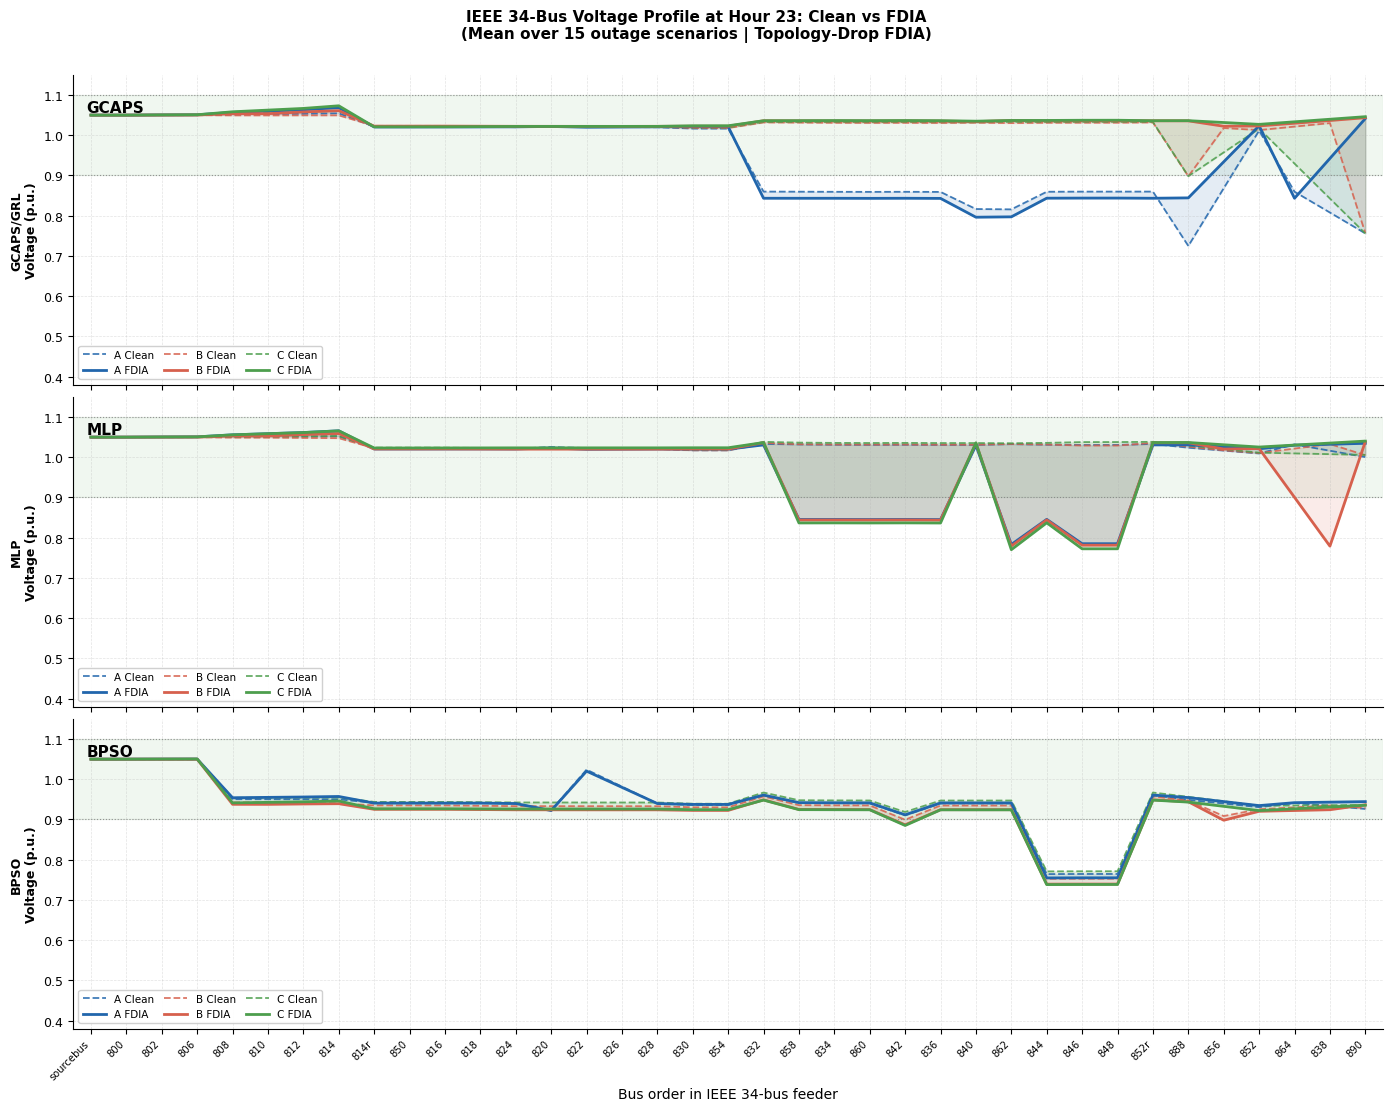

Done.


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

CSV_PATH = r"C:\Users\ISLAS2\Downloads\profile_voltage_bus_phase_34bus.csv"
HOUR = 23

SAVE_PNG = True
SAVE_PDF = True
OUTPUT_PNG = f"voltage_profile_hour{HOUR}_enhanced.png"
OUTPUT_PDF = f"voltage_profile_hour{HOUR}_enhanced.pdf"

METHODS = ["GCAPS", "MLP", "BPSO"]
LABELS = {"GCAPS": "GCAPS/GRL", "MLP": "MLP", "BPSO": "BPSO"}
PHASES = ["A", "B", "C"]

PH_COLOR = {
    "A": "#2166ac",
    "B": "#d6604d",
    "C": "#4d9e4d"
}

V_MIN, V_MAX = 0.90, 1.10

df = pd.read_csv(CSV_PATH)
print(f"Loaded {len(df):,} rows from {CSV_PATH}")

bus_order = (
    df.drop_duplicates("bus")[["bus", "bus_index"]]
    .sort_values("bus_index")
)

bus_list = bus_order["bus"].tolist()
bus_pos = {b: i for i, b in enumerate(bus_list)}

h = df[df["hour"] == HOUR].copy()

agg = (
    h.groupby(
        ["paper_method_label", "mode", "bus", "bus_index", "phase", "phase_active"]
    )["voltage_pu"]
    .mean()
    .reset_index()
)

n_seeds = df["scenario_seed"].nunique()
print(f"Hour={HOUR}, scenarios={n_seeds}. Plotting...")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
    "grid.linewidth": 0.5,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.facecolor": "white",
})

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

fig.suptitle(
    f"IEEE 34-Bus Voltage Profile at Hour {HOUR}: Clean vs FDIA\n"
    f"(Mean over {n_seeds} outage scenarios | Topology-Drop FDIA)",
    fontsize=11,
    fontweight="bold",
    y=1.005
)

for ax, method in zip(axes, METHODS):

    sub = agg[agg["paper_method_label"] == method]

    for phase in PHASES:

        col = PH_COLOR[phase]

        clean = (
            sub[
                (sub["mode"] == "clean_dynamic") &
                (sub["phase"] == phase) &
                (sub["phase_active"] == 1)
            ]
            .sort_values("bus_index")
            .copy()
        )

        attack = (
            sub[
                (sub["mode"] == "attacked_dynamic") &
                (sub["phase"] == phase) &
                (sub["phase_active"] == 1)
            ]
            .sort_values("bus_index")
            .copy()
        )

        xs_clean = [bus_pos[b] for b in clean["bus"].values]
        ys_clean = clean["voltage_pu"].values

        xs_attack = [bus_pos[b] for b in attack["bus"].values]
        ys_attack = attack["voltage_pu"].values

        ax.plot(
            xs_clean,
            ys_clean,
            color=col,
            linestyle="--",
            linewidth=1.3,
            alpha=0.85,
            label=f"{phase} Clean",
            zorder=2
        )

        ax.plot(
            xs_attack,
            ys_attack,
            color=col,
            linestyle="-",
            linewidth=2.0,
            alpha=1.0,
            label=f"{phase} FDIA",
            zorder=3
        )

        if len(xs_clean) == len(xs_attack):
            ax.fill_between(
                xs_clean,
                ys_clean,
                ys_attack,
                color=col,
                alpha=0.12,
                zorder=1
            )

    ax.axhspan(V_MIN, V_MAX, alpha=0.06, color="green", zorder=0)
    ax.axhline(V_MIN, color="gray", linewidth=0.8, linestyle=":", alpha=0.8)
    ax.axhline(V_MAX, color="gray", linewidth=0.8, linestyle=":", alpha=0.8)

    ax.set_ylim(0.38, 1.15)

    ax.set_ylabel(
        f"{LABELS[method]}\nVoltage (p.u.)",
        fontsize=9,
        fontweight="bold"
    )

    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.1f"))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(0.1))

    ax.text(
        0.01,
        0.92,
        method,
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        va="top"
    )

    handles, labels_leg = ax.get_legend_handles_labels()
    ax.legend(
        handles,
        labels_leg,
        fontsize=7.5,
        ncol=3,
        loc="lower left",
        framealpha=0.92,
        handlelength=2.2,
        columnspacing=1.0
    )

axes[-1].set_xticks(range(len(bus_list)))
axes[-1].set_xticklabels(bus_list, rotation=45, ha="right", fontsize=7.2)
axes[-1].set_xlabel("Bus order in IEEE 34-bus feeder", fontsize=10)
axes[-1].set_xlim(-0.5, len(bus_list) - 0.5)

plt.tight_layout(h_pad=0.6)

if SAVE_PNG:
    fig.savefig(OUTPUT_PNG, bbox_inches="tight", dpi=300)
    print(f"Saved: {OUTPUT_PNG}")

if SAVE_PDF:
    fig.savefig(OUTPUT_PDF, bbox_inches="tight", dpi=300)
    print(f"Saved: {OUTPUT_PDF}")

plt.show()
print("Done.")

Loaded 79,920 rows from C:\Users\ISLAS2\Downloads\profile_voltage_bus_phase_34bus.csv
Hour=23, scenarios=15. Plotting...
Saved: voltage_profile_hour23_enhanced.png
Saved: voltage_profile_hour23_enhanced.pdf


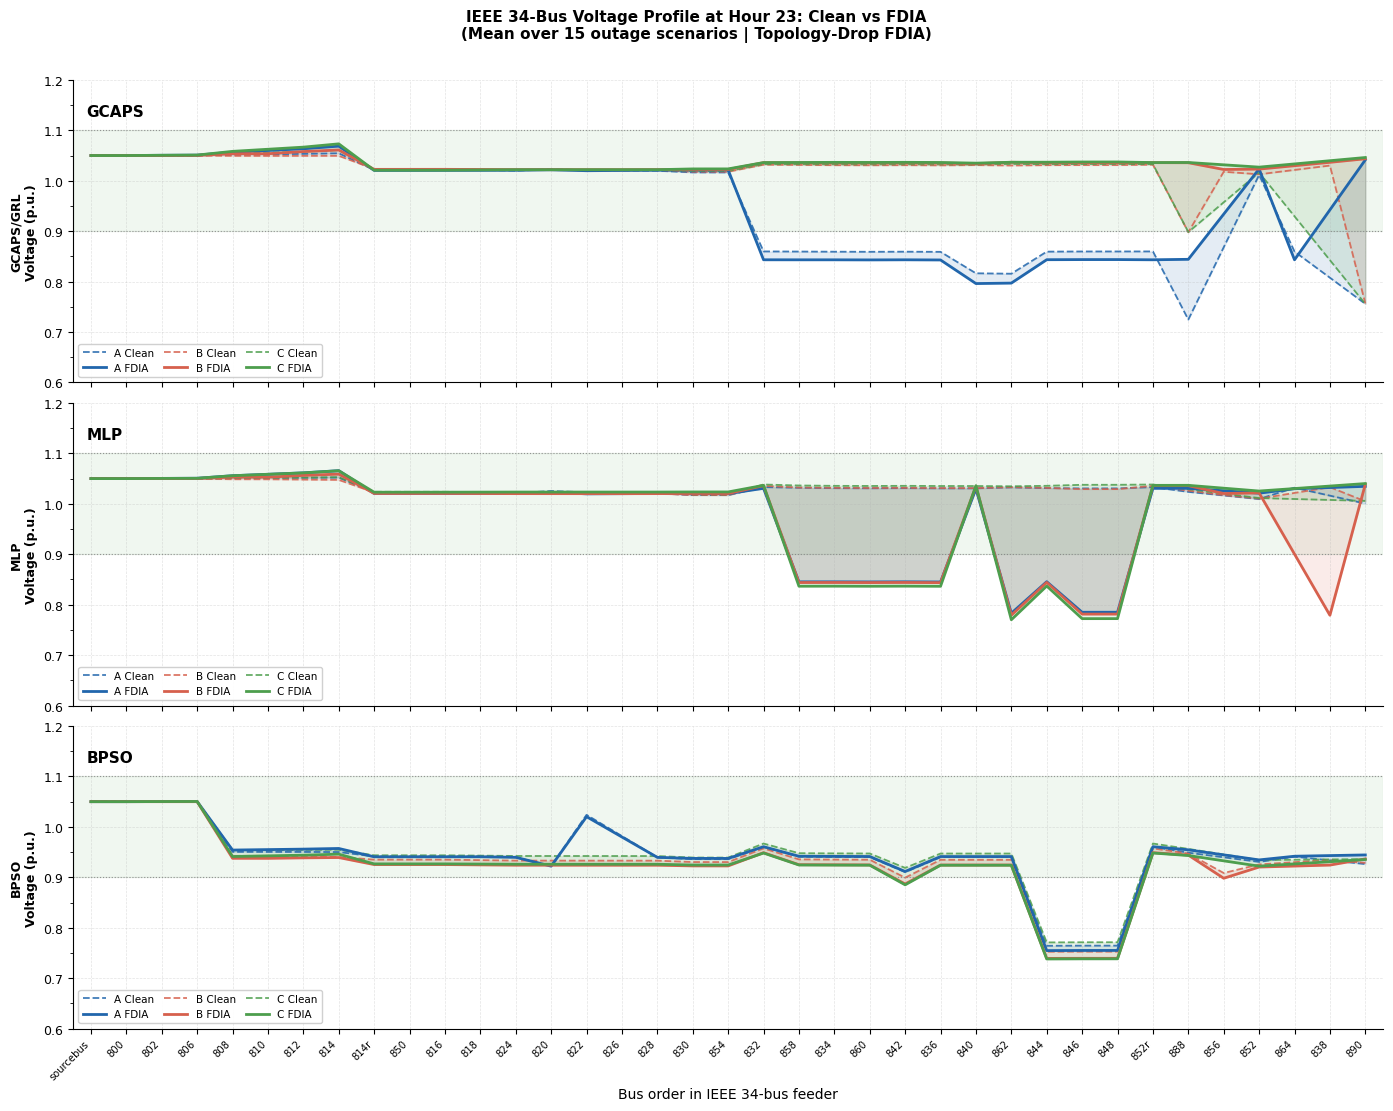

Done.


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

CSV_PATH = r"C:\Users\ISLAS2\Downloads\profile_voltage_bus_phase_34bus.csv"
HOUR = 23

SAVE_PNG = True
SAVE_PDF = True
OUTPUT_PNG = f"voltage_profile_hour{HOUR}_enhanced.png"
OUTPUT_PDF = f"voltage_profile_hour{HOUR}_enhanced.pdf"

METHODS = ["GCAPS", "MLP", "BPSO"]
LABELS = {"GCAPS": "GCAPS/GRL", "MLP": "MLP", "BPSO": "BPSO"}
PHASES = ["A", "B", "C"]

PH_COLOR = {
    "A": "#2166ac",
    "B": "#d6604d",
    "C": "#4d9e4d"
}

V_MIN, V_MAX = 0.90, 1.10

df = pd.read_csv(CSV_PATH)
print(f"Loaded {len(df):,} rows from {CSV_PATH}")

bus_order = (
    df.drop_duplicates("bus")[["bus", "bus_index"]]
    .sort_values("bus_index")
)

bus_list = bus_order["bus"].tolist()
bus_pos = {b: i for i, b in enumerate(bus_list)}

h = df[df["hour"] == HOUR].copy()

agg = (
    h.groupby(
        ["paper_method_label", "mode", "bus", "bus_index", "phase", "phase_active"]
    )["voltage_pu"]
    .mean()
    .reset_index()
)

n_seeds = df["scenario_seed"].nunique()
print(f"Hour={HOUR}, scenarios={n_seeds}. Plotting...")

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
    "grid.linewidth": 0.5,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.facecolor": "white",
})

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

fig.suptitle(
    f"IEEE 34-Bus Voltage Profile at Hour {HOUR}: Clean vs FDIA\n"
    f"(Mean over {n_seeds} outage scenarios | Topology-Drop FDIA)",
    fontsize=11,
    fontweight="bold",
    y=1.005
)

for ax, method in zip(axes, METHODS):

    sub = agg[agg["paper_method_label"] == method]

    for phase in PHASES:

        col = PH_COLOR[phase]

        clean = (
            sub[
                (sub["mode"] == "clean_dynamic") &
                (sub["phase"] == phase) &
                (sub["phase_active"] == 1)
            ]
            .sort_values("bus_index")
            .copy()
        )

        attack = (
            sub[
                (sub["mode"] == "attacked_dynamic") &
                (sub["phase"] == phase) &
                (sub["phase_active"] == 1)
            ]
            .sort_values("bus_index")
            .copy()
        )

        xs_clean = [bus_pos[b] for b in clean["bus"].values]
        ys_clean = clean["voltage_pu"].values

        xs_attack = [bus_pos[b] for b in attack["bus"].values]
        ys_attack = attack["voltage_pu"].values

        ax.plot(
            xs_clean,
            ys_clean,
            color=col,
            linestyle="--",
            linewidth=1.3,
            alpha=0.85,
            label=f"{phase} Clean",
            zorder=2
        )

        ax.plot(
            xs_attack,
            ys_attack,
            color=col,
            linestyle="-",
            linewidth=2.0,
            alpha=1.0,
            label=f"{phase} FDIA",
            zorder=3
        )

        if len(xs_clean) == len(xs_attack):
            ax.fill_between(
                xs_clean,
                ys_clean,
                ys_attack,
                color=col,
                alpha=0.12,
                zorder=1
            )

    ax.axhspan(V_MIN, V_MAX, alpha=0.06, color="green", zorder=0)
    ax.axhline(V_MIN, color="gray", linewidth=0.8, linestyle=":", alpha=0.8)
    ax.axhline(V_MAX, color="gray", linewidth=0.8, linestyle=":", alpha=0.8)

    ax.set_ylim(0.60, 1.20)

    ax.set_ylabel(
        f"{LABELS[method]}\nVoltage (p.u.)",
        fontsize=9,
        fontweight="bold"
    )

    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.1f"))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(0.1))
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.05))

    ax.text(
        0.01,
        0.92,
        method,
        transform=ax.transAxes,
        fontsize=11,
        fontweight="bold",
        va="top"
    )

    handles, labels_leg = ax.get_legend_handles_labels()
    ax.legend(
        handles,
        labels_leg,
        fontsize=7.5,
        ncol=3,
        loc="lower left",
        framealpha=0.92,
        handlelength=2.2,
        columnspacing=1.0
    )

axes[-1].set_xticks(range(len(bus_list)))
axes[-1].set_xticklabels(bus_list, rotation=45, ha="right", fontsize=7.2)
axes[-1].set_xlabel("Bus order in IEEE 34-bus feeder", fontsize=10)
axes[-1].set_xlim(-0.5, len(bus_list) - 0.5)

plt.tight_layout(h_pad=0.6)

if SAVE_PNG:
    fig.savefig(OUTPUT_PNG, bbox_inches="tight", dpi=300)
    print(f"Saved: {OUTPUT_PNG}")

if SAVE_PDF:
    fig.savefig(OUTPUT_PDF, bbox_inches="tight", dpi=300)
    print(f"Saved: {OUTPUT_PDF}")

plt.show()
print("Done.")

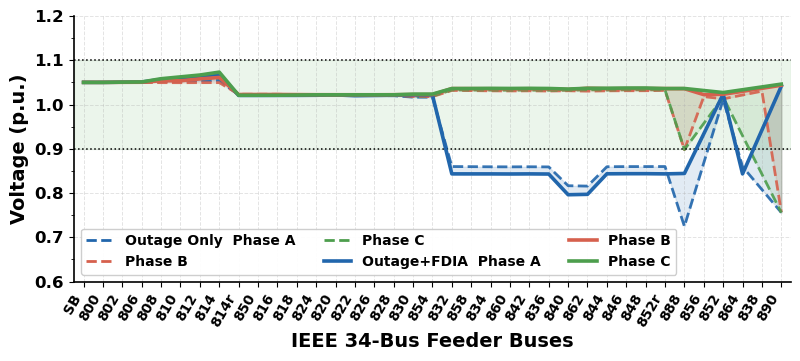

Saved: fig_grl_voltage_profile_hour23.png
Saved: fig_grl_voltage_profile_hour23.pdf


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

CSV_PATH = r"C:\Users\ISLAS2\Downloads\profile_voltage_bus_phase_34bus.csv"
HOUR = 23
OUTPUT_PNG = f"fig_grl_voltage_profile_hour{HOUR}.png"
OUTPUT_PDF = f"fig_grl_voltage_profile_hour{HOUR}.pdf"
METHOD = "GCAPS"   # GCAPS/GRL
PHASES = ["A", "B", "C"]
PH_COLOR = {
    "A": "#2166ac",
    "B": "#d6604d",
    "C": "#4d9e4d"
}
V_MIN, V_MAX = 0.90, 1.10

df = pd.read_csv(CSV_PATH)
df["bus"] = df["bus"].replace("sourcebus", "SB")   # shorten sourcebus label

bus_order = (
    df.drop_duplicates("bus")[["bus", "bus_index"]]
    .sort_values("bus_index")
)
bus_list = bus_order["bus"].tolist()
bus_pos = {b: i for i, b in enumerate(bus_list)}

h = df[df["hour"] == HOUR].copy()
agg = (
    h.groupby(
        ["paper_method_label", "mode", "bus", "bus_index", "phase", "phase_active"]
    )["voltage_pu"]
    .mean()
    .reset_index()
)
sub = agg[agg["paper_method_label"] == METHOD]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 13,
    "axes.labelweight": "bold",
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.facecolor": "white",
})

fig, ax = plt.subplots(figsize=(8.2, 3.8))

for phase in PHASES:
    col = PH_COLOR[phase]
    clean = (
        sub[
            (sub["mode"] == "clean_dynamic") &
            (sub["phase"] == phase) &
            (sub["phase_active"] == 1)
        ]
        .sort_values("bus_index")
        .copy()
    )
    attack = (
        sub[
            (sub["mode"] == "attacked_dynamic") &
            (sub["phase"] == phase) &
            (sub["phase_active"] == 1)
        ]
        .sort_values("bus_index")
        .copy()
    )
    xs_clean  = [bus_pos[b] for b in clean["bus"].values]
    ys_clean  = clean["voltage_pu"].values
    xs_attack = [bus_pos[b] for b in attack["bus"].values]
    ys_attack = attack["voltage_pu"].values

    ax.plot(xs_clean, ys_clean,
            color=col, linestyle="--", linewidth=2.0, alpha=0.9,
            zorder=2)
    ax.plot(xs_attack, ys_attack,
            color=col, linestyle="-", linewidth=2.6, alpha=1.0,
            zorder=3)
    if len(xs_clean) == len(xs_attack):
        ax.fill_between(xs_clean, ys_clean, ys_attack,
                        color=col, alpha=0.13, zorder=1)

ax.axhspan(V_MIN, V_MAX, alpha=0.08, color="green", zorder=0)
ax.axhline(V_MIN, color="black", linewidth=1.1, linestyle=":")
ax.axhline(V_MAX, color="black", linewidth=1.1, linestyle=":")

ax.set_ylim(0.60, 1.20)
ax.set_xlim(-0.5, len(bus_list) - 0.5)
ax.set_ylabel("Voltage (p.u.)", fontsize=14, fontweight="bold")
ax.set_xlabel("IEEE 34-Bus Feeder Buses", fontsize=14, fontweight="bold", labelpad=2)

ax.set_xticks(range(len(bus_list)))
ax.set_xticklabels(bus_list, rotation=60, ha="right", fontsize=10, fontweight="bold")

ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.1f"))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.05))
for tick in ax.get_yticklabels():
    tick.set_fontsize(12)
    tick.set_fontweight("bold")

for spine in ax.spines.values():
    spine.set_linewidth(1.2)
# ── grouped legend: 2 clean rows ──────────────────────────────────────────
legend_elements = [
    # row 1: Outage Only (dashed)
    Line2D([0], [0], color=PH_COLOR["A"], linestyle='--', linewidth=2.0, label='Outage Only  Phase A'),
    Line2D([0], [0], color=PH_COLOR["B"], linestyle='--', linewidth=2.0, label='Phase B'),
    Line2D([0], [0], color=PH_COLOR["C"], linestyle='--', linewidth=2.0, label='Phase C'),
    # row 2: Outage with FDIA (solid)
    Line2D([0], [0], color=PH_COLOR["A"], linestyle='-',  linewidth=2.6, label='Outage+FDIA  Phase A'),
    Line2D([0], [0], color=PH_COLOR["B"], linestyle='-',  linewidth=2.6, label='Phase B'),
    Line2D([0], [0], color=PH_COLOR["C"], linestyle='-',  linewidth=2.6, label='Phase C'),
]

ax.legend(
    handles=legend_elements,
    ncol=3,           # 3 items per row = 2 clean rows
    loc="lower left",
    framealpha=0.95,
    prop={"weight": "bold", "size": 10}
)

plt.tight_layout()
fig.savefig(OUTPUT_PNG, bbox_inches="tight", dpi=600)
fig.savefig(OUTPUT_PDF, bbox_inches="tight", dpi=600)
plt.show()
print(f"Saved: {OUTPUT_PNG}")
print(f"Saved: {OUTPUT_PDF}")

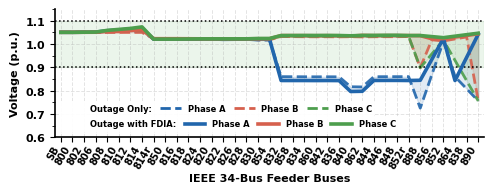

Saved: fig_grl_voltage_profile_hour23.png
Saved: fig_grl_voltage_profile_hour23.pdf


In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

CSV_PATH = r"C:\Users\ISLAS2\Downloads\profile_voltage_bus_phase_34bus.csv"
HOUR = 23
OUTPUT_PNG = f"fig_grl_voltage_profile_hour{HOUR}.png"
OUTPUT_PDF = f"fig_grl_voltage_profile_hour{HOUR}.pdf"
METHOD = "GCAPS"   # GCAPS/GRL
PHASES = ["A", "B", "C"]
PH_COLOR = {
    "A": "#2166ac",
    "B": "#d6604d",
    "C": "#4d9e4d"
}
V_MIN, V_MAX = 0.90, 1.10

df = pd.read_csv(CSV_PATH)
df["bus"] = df["bus"].replace("sourcebus", "SB")

bus_order = (
    df.drop_duplicates("bus")[["bus", "bus_index"]]
    .sort_values("bus_index")
)
bus_list = bus_order["bus"].tolist()
bus_pos = {b: i for i, b in enumerate(bus_list)}

h = df[df["hour"] == HOUR].copy()
agg = (
    h.groupby(
        ["paper_method_label", "mode", "bus", "bus_index", "phase", "phase_active"]
    )["voltage_pu"]
    .mean()
    .reset_index()
)
sub = agg[agg["paper_method_label"] == METHOD]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.labelweight": "bold",
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "xtick.direction": "out",
    "ytick.direction": "out",
    "figure.facecolor": "white",
})

fig, ax = plt.subplots(figsize=(5.1, 2.1))
#fig, ax = plt.subplots(figsize=(7.5, 3.5))


for phase in PHASES:
    col = PH_COLOR[phase]
    clean = (
        sub[
            (sub["mode"] == "clean_dynamic") &
            (sub["phase"] == phase) &
            (sub["phase_active"] == 1)
        ]
        .sort_values("bus_index")
        .copy()
    )
    attack = (
        sub[
            (sub["mode"] == "attacked_dynamic") &
            (sub["phase"] == phase) &
            (sub["phase_active"] == 1)
        ]
        .sort_values("bus_index")
        .copy()
    )
    xs_clean  = [bus_pos[b] for b in clean["bus"].values]
    ys_clean  = clean["voltage_pu"].values
    xs_attack = [bus_pos[b] for b in attack["bus"].values]
    ys_attack = attack["voltage_pu"].values

    ax.plot(xs_clean, ys_clean,
            color=col, linestyle="--", linewidth=2.0, alpha=0.9,
            zorder=2)
    ax.plot(xs_attack, ys_attack,
            color=col, linestyle="-", linewidth=2.6, alpha=1.0,
            zorder=3)
    if len(xs_clean) == len(xs_attack):
        ax.fill_between(xs_clean, ys_clean, ys_attack,
                        color=col, alpha=0.13, zorder=1)

ax.axhspan(V_MIN, V_MAX, alpha=0.08, color="green", zorder=0)
ax.axhline(V_MIN, color="black", linewidth=1.1, linestyle=":")
ax.axhline(V_MAX, color="black", linewidth=1.1, linestyle=":")

ax.set_ylim(0.60, 1.15)
ax.set_xlim(-0.5, len(bus_list) - 0.5)
ax.set_ylabel("Voltage (p.u.)", fontsize=8, fontweight="bold")
ax.set_xlabel("IEEE 34-Bus Feeder Buses", fontsize=8, fontweight="bold", labelpad=2)

ax.set_xticks(range(len(bus_list)))
ax.set_xticklabels(bus_list, rotation=60, ha="right", fontsize=7, fontweight="bold")
ax.tick_params(axis='x', which='major', pad=1)

ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.1f"))
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.1))
ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.05))
for tick in ax.get_yticklabels():
    tick.set_fontsize(8)
    tick.set_fontweight("bold")

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

legend1_elements = [
    Line2D([0], [0], color='none', label='Outage Only:'),          # header text only
    Line2D([0], [0], color=PH_COLOR["A"], linestyle='--', linewidth=2.0, label='Phase A'),
    Line2D([0], [0], color=PH_COLOR["B"], linestyle='--', linewidth=2.0, label='Phase B'),
    Line2D([0], [0], color=PH_COLOR["C"], linestyle='--', linewidth=2.0, label='Phase C'),
]
legend2_elements = [
    Line2D([0], [0], color='none', label='Outage with FDIA:'),          # header text only
    Line2D([0], [0], color=PH_COLOR["A"], linestyle='-', linewidth=2.6, label='Phase A'),
    Line2D([0], [0], color=PH_COLOR["B"], linestyle='-', linewidth=2.6, label='Phase B'),
    Line2D([0], [0], color=PH_COLOR["C"], linestyle='-', linewidth=2.6, label='Phase C'),
]

leg2 = ax.legend(handles=legend2_elements, ncol=4,
                 loc="lower left", bbox_to_anchor=(0.0, 0.01),
                 framealpha=0.95, handlelength=2.5,
                 borderpad=0.4, columnspacing=1.0,
                 prop={"weight": "bold", "size": 6})
leg2.get_frame().set_linewidth(0)

leg1 = ax.legend(handles=legend1_elements, ncol=4,
                 loc="lower left", bbox_to_anchor=(0.0, 0.13),
                 framealpha=0.95, handlelength=2.5,
                 borderpad=0.4, columnspacing=1.0,
                 prop={"weight": "bold", "size": 6})
leg1.get_frame().set_linewidth(0)

ax.add_artist(leg2)

plt.tight_layout()
fig.savefig(OUTPUT_PNG, bbox_inches="tight", dpi=600)
fig.savefig(OUTPUT_PDF, bbox_inches="tight", dpi=600)
plt.show()
print(f"Saved: {OUTPUT_PNG}")
print(f"Saved: {OUTPUT_PDF}")